# Eksperimen Segmentasi Capaian Akademik Level Mata Pelajaran
## Menggunakan *Stability-Aware* K-Means++ (SMA Negeri 1 Jakenan, PAS Semester 1 TA 2023/2024)

Notebook ini mereplikasi pipeline pada paper **"Subject-Level Student Academic Performance Segmentation Using Stability-Aware K-Means++"** dari data mentah `FINAL_Dataset_PAS_SMA_Negeri_1_Jakenan.xlsx`.

**Alur (mengikuti Bab III-V paper):**
1. Audit data & pembersihan (normalisasi label kelas, penanganan `Belum Ikut` dan `Kristen`)
2. Pembentukan 5 kohort kompatibel kurikulum
3. Matriks fitur siswa x mata pelajaran (filter cakupan 80%, imputasi median, z-score)
4. K-Means++ untuk k = 2..8, 30 seed per k (random_state 0-29, `n_init=1`, `max_iter=500`)
5. Evaluasi: Silhouette, Davies-Bouldin, pairwise ARI (435 pasangan)
6. Seleksi multi-objektif (Pareto) + referensi K-Means k=3 (random init, `n_init=10`)
7. Profil klaster pada skala nilai asli, uji sensitivitas ambang 70/80/90%
8. Perbandingan hasil notebook vs angka yang dilaporkan di paper

**Cara pakai di Colab:** simpan file dataset di Google Drive, lalu *Runtime > Run all* dan izinkan akses Drive. Hasil ekspor otomatis tersimpan di folder `hasil_eksperimen_kmeanspp` di Drive.

## 0. Setup

In [3]:
import warnings, itertools, os, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

## 1. Muat dataset dari Google Drive

In [4]:
import glob
from google.colab import drive
drive.mount("/content/drive")

# cari file dataset di seluruh Google Drive
DATA_PATH = glob.glob("/content/drive/MyDrive/Penelitian_PAS_Jakenan/Dataset.xlsx", recursive=True)[0]
raw = pd.read_excel(DATA_PATH, sheet_name="Sheet1")
print("File :", DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File : /content/drive/MyDrive/Penelitian_PAS_Jakenan/Dataset.xlsx
Shape: (19401, 8)


,ABSEN,KELAS,NAMA,NILAI,MATA PELAJARAN,GURU PENGAMPU,NOMOR,HARI KE
0,1,X - 01,Abdul Aziz Bakhrul Awawi,30,Fisika,Suparningsih,1,1
1,2,X - 01,Abdul Diky Ma'urun Irsyad,25,Fisika,Suparningsih,2,1
2,3,X - 01,Abdul Qoid,46,Fisika,Suparningsih,3,1
3,4,X - 01,Adhesta Wahyu Ihtiari,50,Fisika,Suparningsih,4,1
4,5,X - 01,Adinka Aprilia Putri,46,Fisika,Suparningsih,5,1


## 2. Konfigurasi eksperimen
Semua parameter mengikuti Bab IV paper.

In [5]:
CFG = dict(
    COVERAGE_SUBJECT = 0.80,   # subjek dipertahankan jika >=80% siswa kohort punya nilai
    COVERAGE_STUDENT = 0.80,   # siswa dipertahankan jika >=80% fitur terpilih terisi
    K_RANGE          = list(range(2, 9)),
    SEEDS            = list(range(30)),    # random_state 0..29
    MAX_ITER         = 500,
    SENS_THRESHOLDS  = [0.70, 0.80, 0.90],
    REF_K            = 3,
    REF_SEED         = 42,                 # seed referensi k=3 (tidak dispesifikkan paper)
)
COHORTS = ["Grade X", "Grade XI (01-04)", "Grade XI (05-12)", "Grade XII (MIPA)", "Grade XII (IPS)"]

## 3. Audit data mentah (Bab III, Tabel audit)

In [6]:
nilai_num = pd.to_numeric(raw["NILAI"], errors="coerce")
nonnum = raw.loc[nilai_num.isna(), "NILAI"].value_counts()

audit = pd.DataFrame({
    "Audit item": ["Raw PAS records", "Unique student names", "Raw class labels", "Subject labels",
                   "Non-numeric NILAI entries", "  - 'Belum Ikut'", "  - 'Kristen'"],
    "Observed": [len(raw), raw["NAMA"].nunique(), raw["KELAS"].nunique(), raw["MATA PELAJARAN"].nunique(),
                 int(nilai_num.isna().sum()), int(nonnum.get("Belum Ikut", 0)), int(nonnum.get("Kristen", 0))],
})
audit

,Audit item,Observed
0,Raw PAS records,19401
1,Unique student names,1292
2,Raw class labels,38
3,Subject labels,30
4,Non-numeric NILAI entries,243
5,- 'Belum Ikut',221
6,- 'Kristen',22


## 4. Pembersihan data
1. Label kelas lama `XII - IPA n` dinormalisasi menjadi `XII - MIPA n`.
2. Kunci siswa = kelas ternormalisasi + nama.
3. `Belum Ikut` diperlakukan sebagai **missing** (bukan nol).
4. Penanda `Kristen` pada Pendidikan Agama Kristen dibuang **hanya jika** ada nilai numerik untuk kunci siswa-mapel yang sama.

In [7]:
df = raw.copy()
df["KELAS"] = (df["KELAS"].astype(str).str.strip()
               .str.replace(r"^XII - IPA (\d+)", r"XII - MIPA \1", regex=True))
df["NAMA"]  = df["NAMA"].astype(str).str.strip()
df["MAPEL"] = df["MATA PELAJARAN"].astype(str).str.strip()
df["SCORE"] = pd.to_numeric(df["NILAI"], errors="coerce")       # 'Belum Ikut'/'Kristen' -> NaN
df["KEY"]   = df["KELAS"] + " | " + df["NAMA"]

# cek: setiap penanda 'Kristen' punya pasangan numerik?
dup = df[df.duplicated(["KEY", "MAPEL"], keep=False)]
n_dup_pairs = dup.groupby(["KEY", "MAPEL"]).ngroups
has_num = dup.groupby(["KEY", "MAPEL"])["SCORE"].apply(lambda s: s.notna().any())
print(f"Pasangan siswa-mapel berulang : {n_dup_pairs} (baris: {len(dup)})")
print(f"Pasangan dengan pasangan numerik: {int(has_num.sum())} / {len(has_num)}")

# prioritaskan baris numerik lalu hapus duplikat
df = (df.assign(_isnum=df["SCORE"].notna())
        .sort_values("_isnum", ascending=False)
        .drop_duplicates(["KEY", "MAPEL"], keep="first")
        .drop(columns="_isnum"))

print(f"Record setelah pembersihan    : {len(df):,}  (paper: 19,379)")
print(f"Siswa unik                    : {df['KEY'].nunique():,}  (paper: 1,292)")
print(f"Nilai 'Belum Ikut' -> missing : {int((df['NILAI'].astype(str)=='Belum Ikut').sum())}  (paper: 221)")

Pasangan siswa-mapel berulang : 22 (baris: 44)
Pasangan dengan pasangan numerik: 22 / 22
Record setelah pembersihan    : 19,379  (paper: 19,379)
Siswa unik                    : 1,292  (paper: 1,292)
Nilai 'Belum Ikut' -> missing : 221  (paper: 221)


## 5. Kohort kompatibel kurikulum
Kelas X; XI kelas 01-04; XI kelas 05-12; XII MIPA; XII IPS. Pemisahan ini mencegah mapel yang tidak diajarkan diperlakukan sebagai nilai nol.

In [8]:
def assign_cohort(kelas: str) -> str:
    grade, cls = [t.strip() for t in kelas.split(" - ", 1)]
    if grade == "X":
        return "Grade X"
    if grade == "XI":
        return "Grade XI (01-04)" if int(cls) <= 4 else "Grade XI (05-12)"
    return "Grade XII (MIPA)" if cls.startswith("MIPA") else "Grade XII (IPS)"

df["COHORT"] = df["KELAS"].map(assign_cohort)
df.groupby("COHORT")["KEY"].nunique().reindex(COHORTS).rename("Siswa (sebelum filter)").to_frame()

,Siswa (sebelum filter)
COHORT,
Grade X,431
Grade XI (01-04),144
Grade XI (05-12),288
Grade XII (MIPA),286
Grade XII (IPS),143


## 6. Matriks fitur siswa x mata pelajaran (Bab IV-A, IV-B)
- Pivot per kohort
- Subjek dipertahankan jika cakupan >= ambang (default 80%)
- Siswa dipertahankan jika >= 80% fitur terisi
- Imputasi median per subjek per kohort, buang fitur varians nol, lalu z-score

In [9]:
def build_matrix(cohort, thr=0.80, student_thr=0.80):
    g = df[df["COHORT"] == cohort]
    M = g.pivot(index="KEY", columns="MAPEL", values="SCORE")
    cov = M.notna().mean()
    feats = cov[cov >= thr].index.tolist()
    X = M[feats]
    X = X[X.notna().mean(axis=1) >= student_thr]
    n_imputed = int(X.isna().sum().sum())
    X = X.fillna(X.median())
    X = X.loc[:, X.std(ddof=0) > 0]               # buang zero-variance
    Z = StandardScaler().fit_transform(X)
    return X, Z, n_imputed

DATA = {}
rows = []
for c in COHORTS:
    X, Z, imp = build_matrix(c, CFG["COVERAGE_SUBJECT"], CFG["COVERAGE_STUDENT"])
    DATA[c] = dict(X=X, Z=Z)
    rows.append([c, len(X), X.shape[1], imp])

table1 = pd.DataFrame(rows, columns=["Cohort", "Students", "Subject features", "Imputed cells"])
print("TABLE I. Ringkasan matriks fitur (primer, ambang 80%)")
display(table1)
print("Total siswa dipertahankan:", table1["Students"].sum(), " (paper: 1,277)")

TABLE I. Ringkasan matriks fitur (primer, ambang 80%)


,Cohort,Students,Subject features,Imputed cells
0,Grade X,426,16,25
1,Grade XI (01-04),142,13,3
2,Grade XI (05-12),284,10,11
3,Grade XII (MIPA),283,15,22
4,Grade XII (IPS),142,14,25


Total siswa dipertahankan: 1277  (paper: 1,277)


In [10]:
# subjek apa saja yang dipakai per kohort?
for c in COHORTS:
    print(f"{c:18s} ({DATA[c]['X'].shape[1]:2d}):", ", ".join(DATA[c]["X"].columns))

Grade X            (16): Bahasa Indonesia, Bahasa Inggris, Bahasa Jawa, Biologi, Ekonomi, Fisika, Geografi, Informatika, Kimia, Matematika Wajib, PPKn, Pendidikan Agama Islam, Penjasorkes, Sejarah, Seni Budaya, Sosiologi
Grade XI (01-04)   (13): Bahasa Indonesia, Bahasa Indonesia Lanjut, Bahasa Inggris Lanjut, Bahasa Inggris Wajib, Bahasa Jawa, Ekonomi, Matematika Wajib, PKWU, PPKn, Pendidikan Agama Islam, Penjasorkes, Sejarah, Seni Budaya
Grade XI (05-12)   (10): Bahasa Indonesia, Bahasa Inggris Wajib, Bahasa Jawa, Matematika Wajib, PKWU, PPKn, Pendidikan Agama Islam, Penjasorkes, Sejarah, Seni Budaya
Grade XII (MIPA)   (15): Bahasa Indonesia, Bahasa Inggris Wajib, Bahasa Jawa, Bahasa Perancis LM, Biologi, Fisika, Kimia, Matematika Peminatan, Matematika Wajib, PKWU, PPKn, Pendidikan Agama Islam, Penjasorkes, Sejarah Indonesia, Seni Budaya
Grade XII (IPS)    (14): Bahasa Indonesia, Bahasa Inggris Wajib, Bahasa Jawa, Ekonomi, Geografi, Matematika Wajib, PKWU, PPKn, Pendidikan Agama Isla

## 7. Eksperimen K-Means++ berulang (Bab IV-C, IV-D)
Untuk tiap kohort dan tiap k = 2..8, dijalankan 30 inisialisasi. Dihitung Silhouette & DBI per run (seluruh siswa kohort) serta ARI untuk semua 435 pasangan partisi.

In [11]:
def run_kmeanspp(Z, k, seeds, max_iter):
    labs, sil, dbi = [], [], []
    for s in seeds:
        km = KMeans(n_clusters=k, init="k-means++", n_init=1, max_iter=max_iter, random_state=s).fit(Z)
        labs.append(km.labels_)
        sil.append(silhouette_score(Z, km.labels_))
        dbi.append(davies_bouldin_score(Z, km.labels_))
    ari = [adjusted_rand_score(a, b) for a, b in itertools.combinations(labs, 2)]
    return dict(labels=labs, sil=np.array(sil), dbi=np.array(dbi), ari=np.array(ari))

t0 = time.time()
RUNS, summ = {}, []
for c in COHORTS:
    Z = DATA[c]["Z"]
    for k in CFG["K_RANGE"]:
        r = run_kmeanspp(Z, k, CFG["SEEDS"], CFG["MAX_ITER"])
        RUNS[(c, k)] = r
        summ.append(dict(Cohort=c, k=k, N=len(Z),
                         Sil_mean=r["sil"].mean(), Sil_std=r["sil"].std(),
                         DBI_mean=r["dbi"].mean(), DBI_std=r["dbi"].std(),
                         ARI_mean=r["ari"].mean(), ARI_std=r["ari"].std(), n_pairs=len(r["ari"])))
    print(f"  selesai {c}  ({time.time()-t0:.0f}s)")

SUMM = pd.DataFrame(summ)
print("Jumlah pasangan ARI per k:", SUMM["n_pairs"].iloc[0], "(paper: 435)")

  selesai Grade X  (8s)
  selesai Grade XI (01-04)  (13s)
  selesai Grade XI (05-12)  (19s)
  selesai Grade XII (MIPA)  (27s)
  selesai Grade XII (IPS)  (32s)
Jumlah pasangan ARI per k: 435 (paper: 435)


In [12]:
# ringkasan lengkap seluruh k per kohort
for c in COHORTS:
    print("\n==", c, "==")
    display(SUMM[SUMM.Cohort == c].drop(columns=["Cohort", "N", "n_pairs"]).round(3).set_index("k"))


== Grade X ==


,Sil_mean,Sil_std,DBI_mean,DBI_std,ARI_mean,ARI_std
k,,,,,,
2,0.306,0.000,1.205,0.000,1.000,0.000
3,0.204,0.007,1.501,0.040,0.741,0.188
4,0.159,0.002,1.725,0.035,0.779,0.164
5,0.128,0.009,2.085,0.087,0.645,0.139
6,0.118,0.009,2.231,0.132,0.593,0.130
7,0.107,0.008,2.320,0.120,0.572,0.105
8,0.099,0.007,2.387,0.082,0.526,0.077



== Grade XI (01-04) ==


,Sil_mean,Sil_std,DBI_mean,DBI_std,ARI_mean,ARI_std
k,,,,,,
2,0.317,0.001,1.179,0.003,0.960,0.042
3,0.199,0.015,1.493,0.050,0.582,0.217
4,0.168,0.007,1.655,0.058,0.655,0.226
5,0.143,0.012,1.795,0.078,0.579,0.146
6,0.125,0.013,1.912,0.103,0.517,0.129
7,0.116,0.012,1.940,0.111,0.494,0.099
8,0.112,0.011,1.948,0.107,0.458,0.099



== Grade XI (05-12) ==


,Sil_mean,Sil_std,DBI_mean,DBI_std,ARI_mean,ARI_std
k,,,,,,
2,0.289,0.003,1.281,0.008,0.950,0.047
3,0.215,0.005,1.451,0.035,0.804,0.145
4,0.159,0.007,1.720,0.054,0.672,0.240
5,0.136,0.010,1.868,0.083,0.563,0.152
6,0.128,0.008,1.883,0.070,0.480,0.117
7,0.120,0.008,1.881,0.057,0.458,0.099
8,0.120,0.007,1.857,0.084,0.461,0.095



== Grade XII (MIPA) ==


,Sil_mean,Sil_std,DBI_mean,DBI_std,ARI_mean,ARI_std
k,,,,,,
2,0.262,0.001,1.460,0.003,0.971,0.027
3,0.169,0.016,1.799,0.078,0.892,0.168
4,0.125,0.017,2.173,0.170,0.601,0.137
5,0.108,0.011,2.271,0.109,0.522,0.125
6,0.097,0.012,2.326,0.094,0.459,0.094
7,0.091,0.011,2.313,0.118,0.442,0.079
8,0.086,0.010,2.350,0.112,0.403,0.072



== Grade XII (IPS) ==


,Sil_mean,Sil_std,DBI_mean,DBI_std,ARI_mean,ARI_std
k,,,,,,
2,0.230,0.000,1.504,0.000,1.000,0.000
3,0.162,0.003,1.728,0.030,0.751,0.257
4,0.129,0.011,2.024,0.142,0.509,0.133
5,0.114,0.010,2.086,0.132,0.437,0.094
6,0.107,0.010,2.098,0.122,0.417,0.081
7,0.106,0.012,2.027,0.103,0.408,0.086
8,0.102,0.008,2.008,0.102,0.402,0.079


## 8. Seleksi multi-objektif Pareto (Bab IV-E)
Kandidat k *didominasi* jika ada k lain yang minimal sama baiknya pada ketiga objektif (Silhouette naik, ARI naik, DBI turun) dan strictly lebih baik pada setidaknya satu. Dari himpunan Pareto dipilih: Silhouette tertinggi, lalu ARI tertinggi, lalu DBI terendah.

In [13]:
def pareto_front(sub):
    keep = []
    for i, a in sub.iterrows():
        dominated = False
        for j, b in sub.iterrows():
            if i == j: continue
            ge = (b.Sil_mean >= a.Sil_mean) and (b.ARI_mean >= a.ARI_mean) and (b.DBI_mean <= a.DBI_mean)
            gt = (b.Sil_mean >  a.Sil_mean) or  (b.ARI_mean >  a.ARI_mean) or  (b.DBI_mean <  a.DBI_mean)
            if ge and gt: dominated = True; break
        if not dominated: keep.append(i)
    return sub.loc[keep]

SELECTED = {}
sel_rows = []
for c in COHORTS:
    sub = SUMM[SUMM.Cohort == c]
    pf = pareto_front(sub)
    best = pf.sort_values(["Sil_mean", "ARI_mean", "DBI_mean"], ascending=[False, False, True]).iloc[0]
    SELECTED[c] = int(best.k)
    sel_rows.append([c, int(best.N), ", ".join(map(str, pf.k.astype(int))), int(best.k),
                     best.Sil_mean, best.DBI_mean, best.ARI_mean, best.ARI_std])

table2 = pd.DataFrame(sel_rows, columns=["Cohort", "N", "Pareto set (k)", "Selected k",
                                          "Silhouette", "DBI", "Mean ARI", "ARI std"])
print("TABLE II. Solusi terpilih (Pareto)")
display(table2.round(3))

TABLE II. Solusi terpilih (Pareto)


,Cohort,N,Pareto set (k),Selected k,Silhouette,DBI,Mean ARI,ARI std
0,Grade X,426,2,2,0.306,1.205,1.000,0.000
1,Grade XI (01-04),142,2,2,0.317,1.179,0.960,0.042
2,Grade XI (05-12),284,2,2,0.289,1.281,0.950,0.047
3,Grade XII (MIPA),283,2,2,0.262,1.460,0.971,0.027
4,Grade XII (IPS),142,2,2,0.230,1.504,1.000,0.000


### Referensi: K-Means standar k=3 (random init, `n_init=10`) pada matriks fitur yang sama

In [14]:
ref_rows = []
for c in COHORTS:
    Z = DATA[c]["Z"]
    km = KMeans(n_clusters=CFG["REF_K"], init="random", n_init=10, random_state=CFG["REF_SEED"]).fit(Z)
    ref_rows.append([c, len(Z), silhouette_score(Z, km.labels_), davies_bouldin_score(Z, km.labels_)])
table3 = pd.DataFrame(ref_rows, columns=["Cohort", "N", "Silhouette (k=3)", "DBI (k=3)"])
print("TABLE III. Referensi K-Means k=3")
display(table3.round(3))

TABLE III. Referensi K-Means k=3


,Cohort,N,Silhouette (k=3),DBI (k=3)
0,Grade X,426,0.200,1.527
1,Grade XI (01-04),142,0.197,1.533
2,Grade XI (05-12),284,0.219,1.422
3,Grade XII (MIPA),283,0.164,1.828
4,Grade XII (IPS),142,0.162,1.728


## 9. Visualisasi: kualitas klaster vs k (Fig. 1 paper + DBI & ARI)

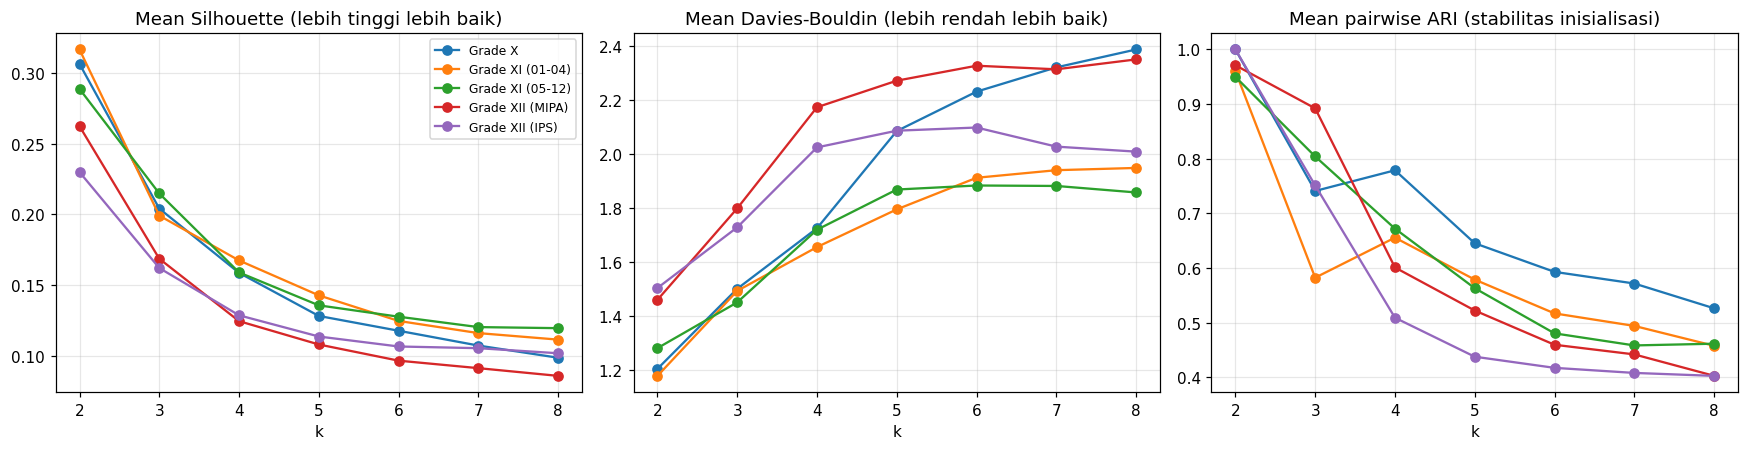

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for c in COHORTS:
    s = SUMM[SUMM.Cohort == c]
    ax[0].plot(s.k, s.Sil_mean, marker="o", label=c)
    ax[1].plot(s.k, s.DBI_mean, marker="o", label=c)
    ax[2].plot(s.k, s.ARI_mean, marker="o", label=c)
ax[0].set_title("Mean Silhouette (lebih tinggi lebih baik)")
ax[1].set_title("Mean Davies-Bouldin (lebih rendah lebih baik)")
ax[2].set_title("Mean pairwise ARI (stabilitas inisialisasi)")
for a in ax: a.set_xlabel("k")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 10. Profil klaster pada skala nilai asli (Bab V, Tabel IV & VI)
Partisi representatif = run (seed) dengan Silhouette tertinggi pada k terpilih. Label *lower-score* / *higher-score* ditentukan dari rata-rata centroid pada skala asli. Ini deskriptif, **bukan** kategori resmi sekolah.

In [16]:
profiles, member_rows, diff_rows = {}, [], []
for c in COHORTS:
    k = SELECTED[c]
    r = RUNS[(c, k)]
    best_seed = int(np.argmax(r["sil"]))
    lab = r["labels"][best_seed]
    X = DATA[c]["X"]
    cent = X.groupby(lab).mean()                       # skala asli
    order = cent.mean(axis=1).sort_values().index.tolist()
    names = {order[0]: "Lower-score", order[-1]: "Higher-score"}
    cent.index = [names.get(i, f"Mid-{i}") for i in cent.index]
    sizes = pd.Series(lab).map(names).value_counts()
    profiles[c] = cent
    for nm in ["Lower-score", "Higher-score"]:
        member_rows.append([c, nm, int(sizes.get(nm, 0)), 100*sizes.get(nm, 0)/len(lab)])
    if k == 2:
        d = (cent.loc["Higher-score"] - cent.loc["Lower-score"]).abs().sort_values(ascending=False).head(3)
        for s in d.index:
            diff_rows.append([c, s, cent.loc["Lower-score", s], cent.loc["Higher-score", s]])

table4 = pd.DataFrame(member_rows, columns=["Cohort", "Profile", "Students", "Pct"])
table4["Membership"] = table4.apply(lambda r: f"{r.Students} ({r.Pct:.1f}%)", axis=1)
print("TABLE IV. Keanggotaan partisi terpilih")
display(table4.pivot(index="Cohort", columns="Profile", values="Membership").reindex(COHORTS))

table6 = pd.DataFrame(diff_rows, columns=["Cohort", "Subject", "Lower centroid", "Higher centroid"])
print("TABLE VI. Subjek dengan selisih centroid terbesar")
display(table6.round(1))

TABLE IV. Keanggotaan partisi terpilih


Profile,Higher-score,Lower-score
Cohort,,
Grade X,225 (52.8%),201 (47.2%)
Grade XI (01-04),79 (55.6%),63 (44.4%)
Grade XI (05-12),185 (65.1%),99 (34.9%)
Grade XII (MIPA),176 (62.2%),107 (37.8%)
Grade XII (IPS),67 (47.2%),75 (52.8%)


TABLE VI. Subjek dengan selisih centroid terbesar


,Cohort,Subject,Lower centroid,Higher centroid
0,Grade X,Kimia,37.5,61.2
1,Grade X,Biologi,37.9,58.0
2,Grade X,PPKn,42.3,61.8
3,Grade XI (01-04),Bahasa Indonesia,52.0,70.7
4,Grade XI (01-04),Bahasa Jawa,66.3,84.8
5,Grade XI (01-04),Bahasa Inggris Lanjut,31.2,48.8
6,Grade XI (05-12),Penjasorkes,32.3,52.3
7,Grade XI (05-12),Seni Budaya,64.5,81.0
8,Grade XI (05-12),Bahasa Indonesia,53.0,69.5
9,Grade XII (MIPA),Fisika,42.2,63.7


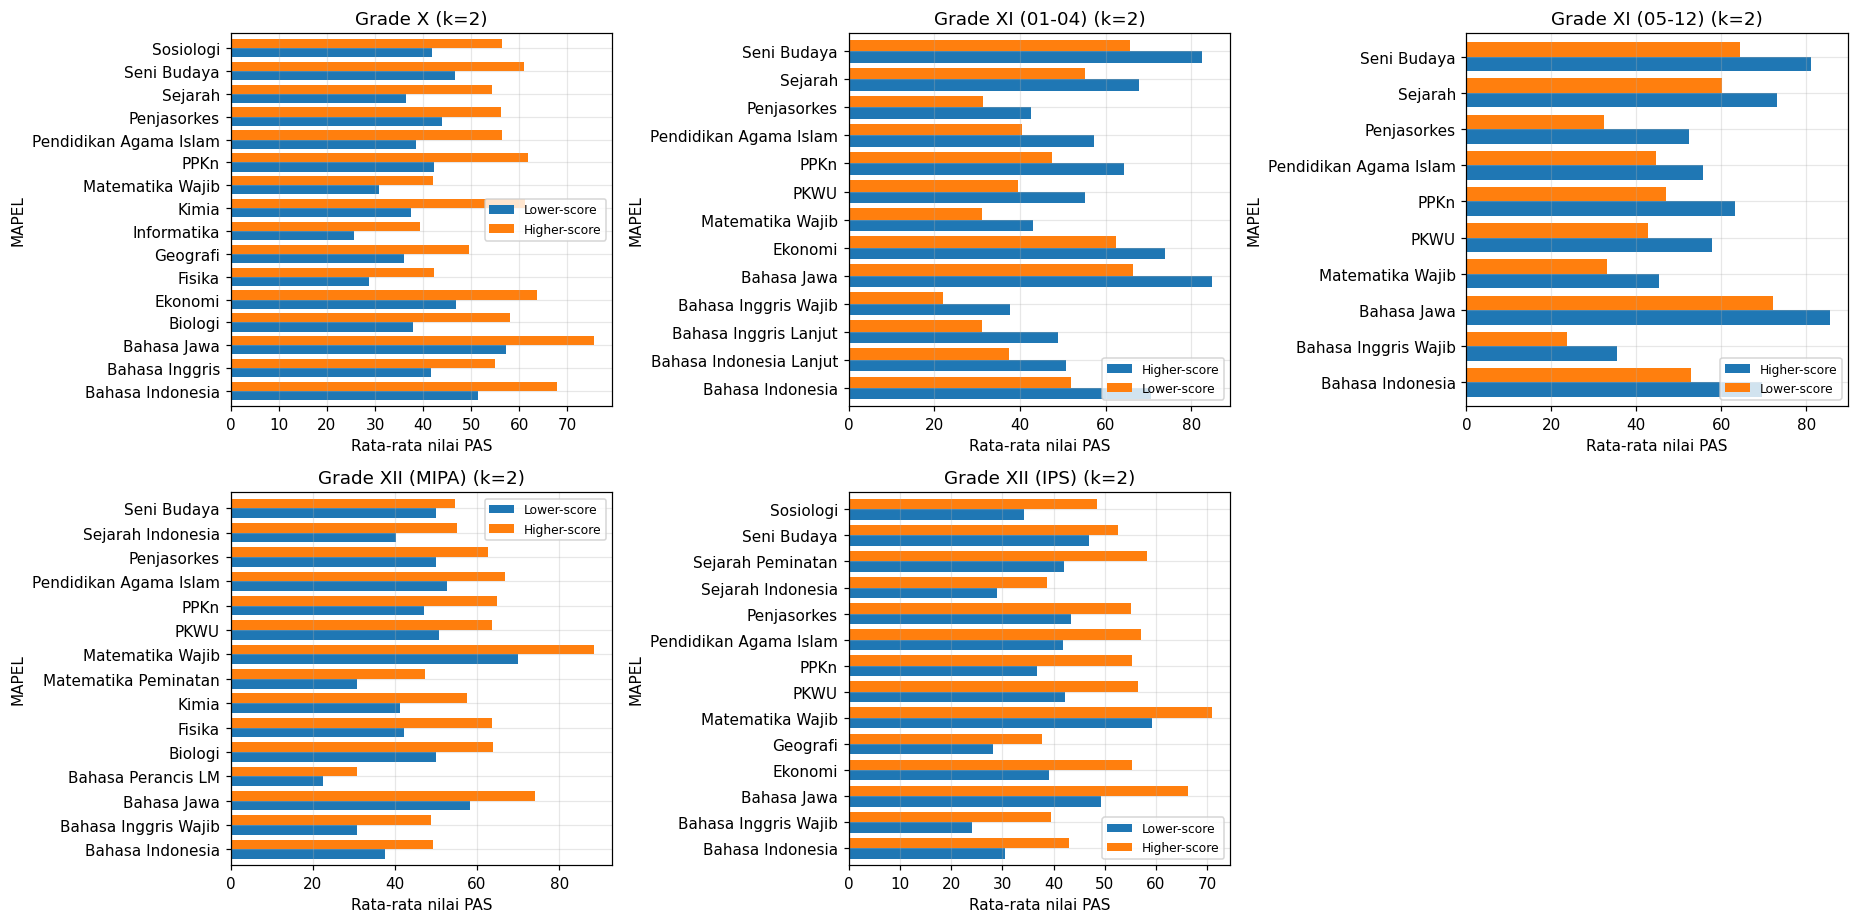

In [17]:
# profil centroid seluruh subjek (skala asli)
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5)); axes = axes.ravel()
for a, c in zip(axes, COHORTS):
    p = profiles[c].T
    p.plot.barh(ax=a, width=.8)
    a.set_title(f"{c} (k={SELECTED[c]})"); a.set_xlabel("Rata-rata nilai PAS"); a.legend(fontsize=8)
axes[-1].axis("off")
plt.tight_layout(); plt.show()

## 11. Uji sensitivitas ambang cakupan fitur (Bab V, Tabel V)

In [18]:
sens = []
for thr in CFG["SENS_THRESHOLDS"]:
    for c in COHORTS:
        X, _, _ = build_matrix(c, thr, CFG["COVERAGE_STUDENT"])
        sens.append([f"{int(thr*100)}%", c, len(X), X.shape[1]])
table5 = pd.DataFrame(sens, columns=["Threshold", "Cohort", "Students", "Features"])
print("TABLE V. Sensitivitas filter cakupan subjek")
display(table5)

TABLE V. Sensitivitas filter cakupan subjek


,Threshold,Cohort,Students,Features
0,70%,Grade X,426,16
1,70%,Grade XI (01-04),142,13
2,70%,Grade XI (05-12),284,10
3,70%,Grade XII (MIPA),283,15
4,70%,Grade XII (IPS),142,15
5,80%,Grade X,426,16
6,80%,Grade XI (01-04),142,13
7,80%,Grade XI (05-12),284,10
8,80%,Grade XII (MIPA),283,15
9,80%,Grade XII (IPS),142,14


## 12. Perbandingan dengan algoritma rival yang dibahas Andre et al. [10]

Bagian ini membandingkan K-Means++ yang diusulkan dengan keluarga algoritma pembanding yang dibahas oleh Andre et al. [10], yaitu random-initialized K-Means, DBSCAN, BIRCH, Gaussian Mixture Model (GMM), dan Mean Shift. Seluruh metode diuji pada matriks fitur terstandardisasi yang sama untuk setiap kohort. Ini merupakan perbandingan metodologis pada dataset PAS SMA Negeri 1 Jakenan, **bukan replikasi eksperimen atau perbandingan angka langsung dengan hasil Andre et al.**

Untuk setiap algoritma, kandidat valid dipilih berdasarkan Silhouette tertinggi. Pada DBSCAN, titik noise (label -1) dikeluarkan dari perhitungan Silhouette dan DBI, sedangkan proporsi noise dilaporkan terpisah. Kandidat dengan kurang dari dua klaster valid atau satu klaster untuk seluruh observasi dinyatakan tidak valid.

In [19]:
# Rival algorithms based on the algorithm families discussed by Andre et al. [10]
# All methods use the same standardized cohort matrix (DATA[c]["Z"]).

from sklearn.cluster import DBSCAN, Birch, MeanShift, estimate_bandwidth
from sklearn.mixture import GaussianMixture

RIVAL_CONFIG = {
    "kmeans_random": {"k_values": list(range(2, 9)), "n_init": 10, "random_state": 42},
    "dbscan": {"eps_values": [0.5, 0.7, 0.9, 1.1, 1.3, 1.5, 1.8, 2.0],
               "min_samples_values": [5, 10]},
    "birch": {"k_values": list(range(2, 9)), "threshold": 0.5},
    "gmm": {"k_values": list(range(2, 9)), "covariance_type": "full",
            "reg_covar": 1e-5, "n_init": 3, "random_state": 42},
    "meanshift": {"quantile": 0.2, "max_sample": 500}
}

def evaluate_partition(Z, labels, exclude_noise=False):
    labels = np.asarray(labels)
    mask = labels != -1 if exclude_noise else np.ones(len(labels), dtype=bool)
    z_eval, lab_eval = Z[mask], labels[mask]
    unique = np.unique(lab_eval)
    # Silhouette/DBI require 2..n-1 clusters in the evaluated observations.
    if len(lab_eval) < 3 or len(unique) < 2 or len(unique) >= len(lab_eval):
        return None
    return {
        "silhouette": float(silhouette_score(z_eval, lab_eval)),
        "dbi": float(davies_bouldin_score(z_eval, lab_eval)),
        "n_clusters": int(len(unique)),
        "n_evaluated": int(len(lab_eval)),
        "noise_ratio": float(np.mean(labels == -1)) if exclude_noise else 0.0
    }

def rival_candidates(Z):
    rows = []

    # 1) Random-initialized K-Means
    for k in RIVAL_CONFIG["kmeans_random"]["k_values"]:
        t0 = time.time()
        model = KMeans(n_clusters=k, init="random", n_init=10,
                       random_state=42, max_iter=CFG["MAX_ITER"])
        labels = model.fit_predict(Z)
        met = evaluate_partition(Z, labels)
        if met:
            rows.append(dict(Algorithm="Random K-Means", Configuration=f"k={k}, n_init=10",
                             **met, runtime_sec=time.time()-t0))

    # 2) DBSCAN; noise points are excluded from internal metric calculations
    for eps in RIVAL_CONFIG["dbscan"]["eps_values"]:
        for ms in RIVAL_CONFIG["dbscan"]["min_samples_values"]:
            t0 = time.time()
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
            met = evaluate_partition(Z, labels, exclude_noise=True)
            if met:
                rows.append(dict(Algorithm="DBSCAN", Configuration=f"eps={eps}, min_samples={ms}",
                                 **met, runtime_sec=time.time()-t0))

    # 3) BIRCH
    for k in RIVAL_CONFIG["birch"]["k_values"]:
        t0 = time.time()
        labels = Birch(threshold=0.5, n_clusters=k).fit_predict(Z)
        met = evaluate_partition(Z, labels)
        if met:
            rows.append(dict(Algorithm="BIRCH", Configuration=f"n_clusters={k}, threshold=0.5",
                             **met, runtime_sec=time.time()-t0))

    # 4) Gaussian Mixture Model
    for k in RIVAL_CONFIG["gmm"]["k_values"]:
        t0 = time.time()
        model = GaussianMixture(n_components=k, covariance_type="full",
                                reg_covar=1e-5, n_init=3, random_state=42)
        labels = model.fit_predict(Z)
        met = evaluate_partition(Z, labels)
        if met:
            rows.append(dict(Algorithm="GMM", Configuration=f"components={k}, covariance=full",
                             **met, runtime_sec=time.time()-t0))

    # 5) Mean Shift
    t0 = time.time()
    bandwidth = estimate_bandwidth(
        Z, quantile=0.2, n_samples=min(500, len(Z)), random_state=42
    )
    if bandwidth is not None and np.isfinite(bandwidth) and bandwidth > 0:
        labels = MeanShift(bandwidth=bandwidth, bin_seeding=True).fit_predict(Z)
        met = evaluate_partition(Z, labels)
        if met:
            rows.append(dict(Algorithm="Mean Shift", Configuration=f"bandwidth={bandwidth:.6g}, quantile=0.2",
                             **met, runtime_sec=time.time()-t0))
    return pd.DataFrame(rows)

rival_all = []
for c in COHORTS:
    print(f"Menjalankan algoritma rival: {c}")
    candidates = rival_candidates(DATA[c]["Z"])
    if not candidates.empty:
        candidates.insert(0, "Cohort", c)
        rival_all.append(candidates)

RIVAL_RESULTS = (pd.concat(rival_all, ignore_index=True)
                 if rival_all else pd.DataFrame())

if not RIVAL_RESULTS.empty:
    # Best valid configuration per algorithm and cohort, ranked by Silhouette.
    RIVAL_BEST = (RIVAL_RESULTS.sort_values(
        ["Cohort", "Algorithm", "silhouette", "dbi"],
        ascending=[True, True, False, True]
    ).groupby(["Cohort", "Algorithm"], as_index=False).first())
    RIVAL_BEST = RIVAL_BEST[[
        "Cohort", "Algorithm", "Configuration", "n_clusters",
        "silhouette", "dbi", "noise_ratio", "n_evaluated", "runtime_sec"
    ]]
    print("Tabel 12A. Konfigurasi rival terbaik per kohort (ranking Silhouette)")
    display(RIVAL_BEST.round(4))
    print("Tabel 12B. Seluruh kandidat valid")
    display(RIVAL_RESULTS.round(4))
else:
    RIVAL_BEST = pd.DataFrame()
    print("Tidak ada kandidat rival valid. Periksa matriks fitur atau parameter.")


Menjalankan algoritma rival: Grade X
Menjalankan algoritma rival: Grade XI (01-04)
Menjalankan algoritma rival: Grade XI (05-12)
Menjalankan algoritma rival: Grade XII (MIPA)
Menjalankan algoritma rival: Grade XII (IPS)
Tabel 12A. Konfigurasi rival terbaik per kohort (ranking Silhouette)


,Cohort,Algorithm,Configuration,n_clusters,silhouette,dbi,noise_ratio,n_evaluated,runtime_sec
0,Grade X,BIRCH,"n_clusters=2, threshold=0.5",2,0.2833,1.2409,0.0000,426,0.1418
1,Grade X,DBSCAN,"eps=2.0, min_samples=5",3,0.4564,0.7697,0.9131,37,0.0078
2,Grade X,GMM,"components=2, covariance=full",2,0.2014,1.5773,0.0000,426,0.4339
3,Grade X,Random K-Means,"k=2, n_init=10",2,0.3064,1.2047,0.0000,426,0.0247
4,Grade XI (01-04),BIRCH,"n_clusters=2, threshold=0.5",2,0.3155,1.1812,0.0000,142,0.0108
5,Grade XI (01-04),DBSCAN,"eps=2.0, min_samples=5",5,0.1446,1.6795,0.7254,39,0.0053
6,Grade XI (01-04),GMM,"components=2, covariance=full",2,0.2496,1.3493,0.0000,142,0.0664
7,Grade XI (01-04),Random K-Means,"k=2, n_init=10",2,0.3174,1.1762,0.0000,142,0.0107
8,Grade XI (05-12),BIRCH,"n_clusters=2, threshold=0.5",2,0.3733,0.9883,0.0000,284,0.0250
9,Grade XI (05-12),DBSCAN,"eps=1.3, min_samples=5",2,0.3888,0.9390,0.9507,14,0.0101


Tabel 12B. Seluruh kandidat valid


,Cohort,Algorithm,Configuration,silhouette,dbi,n_clusters,n_evaluated,noise_ratio,runtime_sec
0,Grade X,Random K-Means,"k=2, n_init=10",0.3064,1.2047,2,426,0.0,0.0247
1,Grade X,Random K-Means,"k=3, n_init=10",0.2002,1.5269,3,426,0.0,0.0300
2,Grade X,Random K-Means,"k=4, n_init=10",0.1611,1.6941,4,426,0.0,0.0372
3,Grade X,Random K-Means,"k=5, n_init=10",0.1240,2.1086,5,426,0.0,0.0358
4,Grade X,Random K-Means,"k=6, n_init=10",0.1249,2.0763,6,426,0.0,0.0836
...,...,...,...,...,...,...,...,...,...
107,Grade XII (IPS),GMM,"components=4, covariance=full",0.0905,2.2412,4,142,0.0,0.0642
108,Grade XII (IPS),GMM,"components=5, covariance=full",0.0890,2.2945,5,142,0.0,0.0738
109,Grade XII (IPS),GMM,"components=6, covariance=full",0.1000,2.0713,6,142,0.0,0.0728
110,Grade XII (IPS),GMM,"components=7, covariance=full",0.0731,2.1282,7,142,0.0,0.0715


## 13. Ekspor hasil dan pemeriksaan kelengkapan

Workbook akhir berisi audit, matriks fitur, seluruh metrik K-Means++, seleksi Pareto, baseline k=3, sensitivitas, profil centroid, serta hasil semua kandidat rival dan konfigurasi rival terbaik. Pemeriksaan otomatis memastikan 5 cohort, 35 konfigurasi utama, 30 seed per konfigurasi, dan 435 pasangan ARI.

**Privasi:** workbook publik hanya berisi hasil agregat dan profil. Identitas siswa serta label klaster tingkat individu tidak diekspor. Simpan dataset asli hanya di lokasi yang aksesnya dibatasi.


### Pemeriksaan hasil sebelum ekspor
Cell ekspor berikut akan menghentikan proses jika eksperimen utama tidak lengkap atau jumlah siswa hasil preprocessing tidak sesuai dengan rancangan paper.

In [21]:
# Ekspor hasil agregat dan tabel eksperimen.
# Jangan mengekspor KEY/NAMA atau daftar label per siswa ke workbook publik.
OUT_DIR = "/content/drive/MyDrive/Penelitian_PAS_Jakenan/Output"
os.makedirs(OUT_DIR, exist_ok=True)
OUT = os.path.join(OUT_DIR, "hasil_eksperimen_kmeanspp_FINAL.xlsx")

# Pemeriksaan kelengkapan eksperimen utama sebelum ekspor.
expected_runs = len(COHORTS) * len(CFG["K_RANGE"]) * len(CFG["SEEDS"])
actual_runs = sum(len(RUNS[(c, k)]["sil"]) for c in COHORTS for k in CFG["K_RANGE"])
assert actual_runs == expected_runs, f"Run K-Means++ tidak lengkap: {actual_runs}/{expected_runs}"
assert (SUMM["n_pairs"] == 435).all(), "Ada konfigurasi dengan jumlah pasangan ARI bukan 435."
assert len(table1) == 5 and int(table1["Students"].sum()) == 1277, (
    "Jumlah cohort/siswa berbeda dari audit paper; periksa preprocessing sebelum interpretasi."
)

# Ringkasan status rival: algoritma yang tidak menghasilkan kandidat valid tetap terlihat.
expected_rivals = ["Random K-Means", "DBSCAN", "BIRCH", "GMM", "Mean Shift"]
rival_status_rows = []
for c in COHORTS:
    for alg in expected_rivals:
        n = 0 if RIVAL_RESULTS.empty else int(
            ((RIVAL_RESULTS["Cohort"] == c) & (RIVAL_RESULTS["Algorithm"] == alg)).sum()
        )
        rival_status_rows.append([c, alg, n, "Valid candidates found" if n else "No valid candidate"])
RIVAL_STATUS = pd.DataFrame(
    rival_status_rows, columns=["Cohort", "Algorithm", "Valid candidate count", "Status"]
)

with pd.ExcelWriter(OUT) as xw:
    audit.to_excel(xw, sheet_name="Audit", index=False)
    table1.to_excel(xw, sheet_name="T1_FeatureMatrix", index=False)
    SUMM.round(6).to_excel(xw, sheet_name="AllK_Metrics", index=False)
    table2.round(6).to_excel(xw, sheet_name="T2_Selected", index=False)
    table3.round(6).to_excel(xw, sheet_name="T3_Ref_k3", index=False)
    table4.drop(columns="Membership").round(4).to_excel(xw, sheet_name="T4_Membership", index=False)
    table5.to_excel(xw, sheet_name="T5_Sensitivity", index=False)
    table6.round(4).to_excel(xw, sheet_name="T6_Centroid", index=False)
    RIVAL_STATUS.to_excel(xw, sheet_name="Rival_Status", index=False)
    if not RIVAL_RESULTS.empty:
        RIVAL_BEST.round(6).to_excel(xw, sheet_name="Rival_Best", index=False)
        RIVAL_RESULTS.round(6).to_excel(xw, sheet_name="Rival_All_Candidates", index=False)
    for c in COHORTS:
        sheet = ("Prof_" + c.replace("Grade ", "").replace(" ", "").replace("(", "").replace(")", "").replace("-", ""))[:31]
        profiles[c].round(4).to_excel(xw, sheet_name=sheet)

print("Eksperimen utama:", actual_runs, "/", expected_runs, "run")
print("Pasangan ARI per konfigurasi:", sorted(SUMM["n_pairs"].unique()))
print("Rival valid candidates:", len(RIVAL_RESULTS))
print("File hasil:", OUT)

from google.colab import files
files.download(OUT)


Eksperimen utama: 1050 / 1050 run
Pasangan ARI per konfigurasi: [np.int64(435)]
Rival valid candidates: 112
File hasil: /content/drive/MyDrive/Penelitian_PAS_Jakenan/Output/hasil_eksperimen_kmeanspp_FINAL.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Catatan interpretasi & keterbatasan

- Data berasal dari satu sekolah dan satu semester PAS; validasi eksternal belum dilakukan.
- ARI berpasangan mengukur repeatability akibat inisialisasi pada matriks siswa yang sama, bukan stabilitas akibat resampling atau perubahan semester.
- Lima algoritma rival mengikuti keluarga metode yang dibahas Andre et al. [10]. Eksperimen ini bukan replikasi persis atas dataset, parameter, atau hasil Andre et al.
- Konfigurasi rival terbaik dipilih berdasarkan Silhouette pada matriks yang sama; perbandingan bersifat eksploratif dan dapat mengalami optimistic selection.
- Untuk DBSCAN, noise (`label = -1`) dikeluarkan dari perhitungan Silhouette dan DBI; proporsi noise dilaporkan terpisah.
- Tidak ada ground-truth label sehingga accuracy, precision, recall, dan F1-score tidak digunakan.
- Jangan mempublikasikan nama siswa, nomor absen, KEY, atau label klaster individu. Pastikan izin sekolah dan tata kelola data dipenuhi.
